In [5]:
import os
from keras.utils import image_dataset_from_directory

In [29]:
batch_size = 32
image_size = (224, 224)
epochs = 25

In [7]:
dataset = "../../exercises/week9/bahrain/"

In [18]:
base_dir = '.'
data_dir = os.path.join(base_dir, "bahrain")

train_dir = os.path.join(data_dir, "train")
val_dir = os.path.join(data_dir, "valid")
test_dir = os.path.join(data_dir, "test")#creating the datasets

In [20]:
train_dataset = image_dataset_from_directory(
    train_dir,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical", #categorical because we're dealing with many classes
    shuffle=True
)

validation_dataset = image_dataset_from_directory(
    val_dir,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical",
    shuffle=False
)

test_dataset = image_dataset_from_directory(
    test_dir,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical",
    shuffle=False
)


Found 81 files belonging to 5 classes.
Found 10 files belonging to 5 classes.
Found 14 files belonging to 5 classes.


In [24]:
for data_batch, label_batch in train_dataset.take(1):
    print('data batch shape ', data_batch.shape)
    print('label batch shape ', label_batch.shape)

data batch shape  (32, 224, 224, 3)
label batch shape  (32, 5)


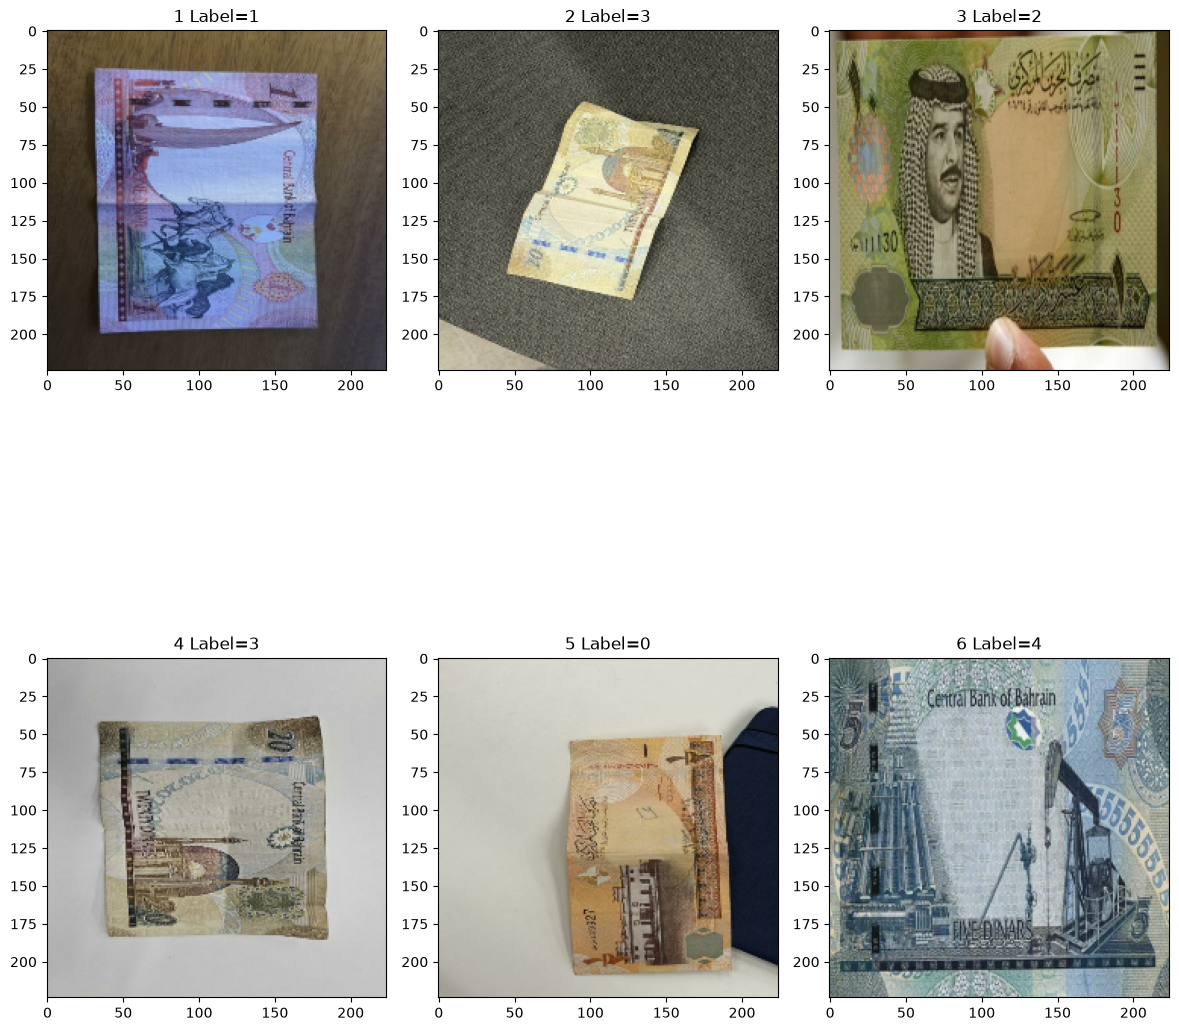

In [25]:
import matplotlib.pyplot as plt
import numpy as np

fig=plt.figure(figsize=(12,15))
columns = 3
rows = 2

for i in range(1, 7):
    img = data_batch[i]/255
    ax =fig.add_subplot(rows, columns, i)

    lbl = str(np.argmax(label_batch[i]))

    fig.tight_layout()
    ax.title.set_text(str(i)+ " Label=" + lbl)
    plt.imshow(img)
plt.show()

In [34]:
import keras
from keras import models, layers, regularizers
from keras.applications import VGG16
#from keras.applications.vgg16 import preprocess_input

vgg_base = VGG16(weights='imagenet', include_top=False,input_shape=(224,224,3)) #(150,150,3)
vgg_base.trainable = False

network = models.Sequential()
network.add(layers.Input(shape=(224,224,3)))

#network.add(layers.RandomFlip("horizontal")
network.add(layers.RandomRotation(0.05))
network.add(layers.RandomZoom(0.05))    
#network.add(layers.RandomContrast(0.2))

#network.add(layers.Lambda(preprocess_input))

network.add(vgg_base)
network.add(layers.GlobalAveragePooling2D())

network.add(layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(0.005)))
network.add(layers.Dropout(0.2))

network.add(layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.0001)))
network.add(layers.Dropout(0.2))

network.add(layers.Dense(5, activation='softmax'))

network.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation_2               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,109,957 (57.64 MB)

 Trainable params: 395,269 (1.51 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [35]:
#from tensorflow.keras import optimizers
from keras import callbacks

#callbacks help to save intermediate results.

callbacks_vgg = [callbacks.ModelCheckpoint(
                filepath = "money_vgg.keras",
                save_best_only=True,
                monitor="val_loss"),

                callbacks.EarlyStopping(
                monitor="val_loss",
                patience=6,
                restore_best_weights=True),
            ]

# network.compile(loss='binary_crossentropy', optimizer=optimizers.RMSprop(learning_rate=1e-4), metrics=['acc']) # alternative showing use of learning rate
network.compile(loss='categorical_crossentropy', optimizer="adam", metrics=['acc'])

history_vgg = network.fit(train_dataset, epochs=epochs, validation_data=validation_dataset,callbacks=callbacks_vgg)

Epoch 1/25


3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 3s/step - acc: 0.2716 - loss: 7.0648 - val_acc: 0.5000 - val_loss: 6.1091
Epoch 2/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 9s 3s/step - acc: 0.4198 - loss: 5.0618 - val_acc: 0.6000 - val_loss: 3.7501
Epoch 3/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 3s/step - acc: 0.5926 - loss: 3.7139 - val_acc: 0.6000 - val_loss: 4.0385
Epoch 4/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 9s 3s/step - acc: 0.7284 - loss: 3.2267 - val_acc: 0.8000 - val_loss: 2.8969
Epoch 5/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 3s/step - acc: 0.7160 - loss: 3.1340 - val_acc: 0.6000 - val_loss: 3.3760
Epoch 6/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 3s/step - acc: 0.7037 - loss: 3.2395 - val_acc: 0.8000 - val_loss: 3.1369
Epoch 7/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - acc: 0.9136 - loss: 2.6836 - val_acc: 0.7000 - val_loss: 3.4490
Epoch 8/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - acc: 0.8889 - loss: 2.6325 - val_acc: 0.7000 - val_loss: 3.7091
Epoch 9/25
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - acc: 0.8765 - loss: 2.6201 - val_acc: 0.8000 - val_loss

In [36]:
import matplotlib.pyplot as plt

acc = history_vgg.history['acc']
val_acc = history_vgg.history['val_acc']
loss = history_vgg.history['loss']
val_loss = history_vgg.history['val_loss']
epocs = range(1, len(acc)+1)

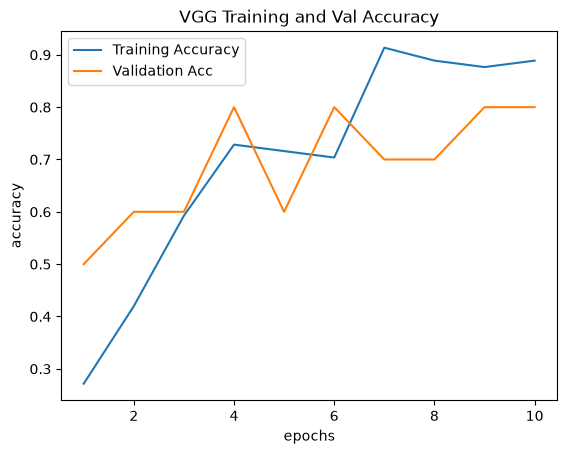

In [37]:
plt.plot(epocs, acc, label='Training Accuracy')
plt.plot(epocs, val_acc, label='Validation Acc')
plt.legend()
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.title('VGG Training and Val Accuracy')
plt.show()

In [38]:
from keras import models

test_model = models.load_model("money_vgg.keras")

test_loss, test_acc = test_model.evaluate(test_dataset)
print("VGG Test Accuracy =", test_acc)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - acc: 0.5714 - loss: 3.4848
VGG Test Accuracy = 0.5714285969734192


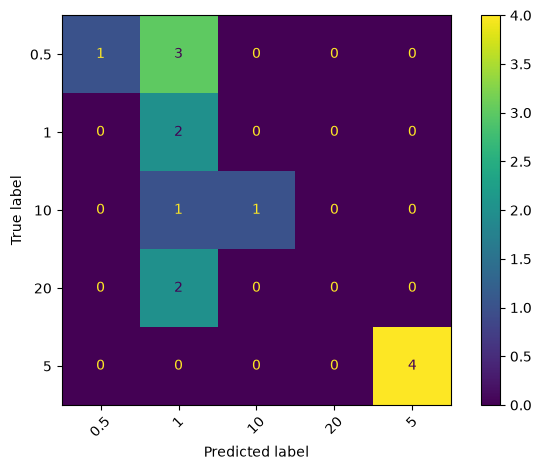

In [40]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=labels,
    xticks_rotation=45,
    values_format='d'
)

plt.tight_layout()
plt.show()

In [1]:
#YOLO
from ultralytics import YOLO

In [2]:
model = YOLO("yolo26n.pt")

In [3]:
#!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="VzetYflr25UfCYKP62UH")
project = rf.workspace("mohameds-workspace-wg0dv").project("bahraini-currency")
version = project.version(1)
dataset = version.download("yolo26")

loading Roboflow workspace...
loading Roboflow project...


In [5]:
import os
print(os.listdir(dataset.location))

['data.yaml', 'README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'valid']


In [6]:
results = model.train(
    data=os.path.join(dataset.location, "data.yaml"),
    epochs=30,
    imgsz=320,
    batch=2,
    device="cpu"
)

Ultralytics 8.4.197  Python-3.12.0 torch-2.14.1+cu126 CPU (AMD Ryzen 5 4600H with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\user\PycharmProjects\GA\excercises\week9\bahraini-currency-1\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0

In [13]:
from ultralytics import YOLO

model = YOLO("train-7/weights/best.pt")

In [30]:
results = model.predict(
    source="bahrain/test/5/5_0006_png.rf.b2a11293982561608150a02795958c2f.jpg",
    save=True,
    device="cpu"
)


    #10/10_0006_png.rf.db9888df3e8b4c181909f8b0ae190912.jpg
    #20/20_0017_jpg.rf.03ebbc7bc3f8e982ced69fbfa8bbbc39.jpg
    #10/10_0001_png.rf.12e7a7e6bad8226ba404acb4cc4afdd6.jpg
    #1/1_0006_jpg.rf.c70a46500afe0e12b7cfd963300638c4.jpg
    #5/5_0006_png.rf.b2a11293982561608150a02795958c2f.jpg
    


image 1/1 c:\Users\user\PycharmProjects\GA\excercises\week9\bahrain\test\5\5_0006_png.rf.b2a11293982561608150a02795958c2f.jpg: 320x320 1 5, 42.5ms
Speed: 1.4ms preprocess, 42.5ms inference, 1.3ms postprocess per image at shape (1, 3, 320, 320)
Results saved to C:\Users\user\runs\detect\predict-2


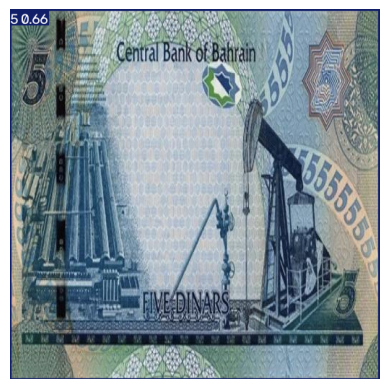

In [31]:
import matplotlib.pyplot as plt

plt.imshow(results[0].plot()[:, :, ::-1])
plt.axis("off")
plt.show()

In [32]:
print(model.names)

{0: '0_5', 1: '1', 2: '10', 3: '20', 4: '5'}


In [33]:
import os

print("Current directory:", os.getcwd())
print("Model exists:", os.path.exists("train-7/weights/best.pt"))

Current directory: c:\Users\user\PycharmProjects\GA\excercises\week9
Model exists: True
